In [1]:
#load the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings # any library will give you future warnings regarding updates in functions. To ignore it write this line
warnings.filterwarnings('ignore')

In [2]:
weather=pd.read_csv("data_clean.csv")

In [3]:
weather.head()

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2010,67,S
1,2,36.0,118.0,8.0,72,5,2,2010,72,C
2,3,12.0,149.0,12.6,74,5,3,2010,74,PS
3,4,18.0,313.0,11.5,62,5,4,2010,62,S
4,5,NaN,NaN,14.3,56,5,5,2010,56,S


#### Observations:
1. null values are present
2. weather is a categorical data
3. unnamd:0 is just index numbers
4. solar.r rename
5. temp and temp c looks alike


In [4]:
weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  158 non-null    int64  
 1   Ozone       120 non-null    float64
 2   Solar.R     151 non-null    float64
 3   Wind        158 non-null    float64
 4   Temp C      158 non-null    object 
 5   Month       158 non-null    object 
 6   Day         158 non-null    int64  
 7   Year        158 non-null    int64  
 8   Temp        158 non-null    int64  
 9   Weather     155 non-null    object 
dtypes: float64(3), int64(4), object(3)
memory usage: 12.5+ KB


#### Observations
1. Ozone, solar, and weather with null values
2. Month nd Temp c reading as object


In [5]:
weather.describe()

,Unnamed: 0,Ozone,Solar.R,Wind,Day,Year,Temp
count,158.000000,120.000000,151.000000,158.000000,158.000000,158.0,158.000000
mean,79.500000,41.583333,185.403974,9.957595,16.006329,2010.0,77.727848
std,45.754781,32.620709,88.723103,3.511261,8.997166,0.0,9.377877
min,1.000000,1.000000,7.000000,1.700000,1.000000,2010.0,56.000000
25%,40.250000,18.000000,119.000000,7.400000,8.000000,2010.0,72.000000
50%,79.500000,30.500000,197.000000,9.700000,16.000000,2010.0,78.500000
75%,118.750000,61.500000,257.000000,11.875000,24.000000,2010.0,84.000000
max,158.000000,168.000000,334.000000,20.700000,31.000000,2010.0,97.000000


In [7]:
weather.drop_duplicates(inplace=True)

In [8]:
weather

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2010,67,S
1,2,36.0,118.0,8.0,72,5,2,2010,72,C
2,3,12.0,149.0,12.6,74,5,3,2010,74,PS
3,4,18.0,313.0,11.5,62,5,4,2010,62,S
4,5,NaN,NaN,14.3,56,5,5,2010,56,S
...,...,...,...,...,...,...,...,...,...,...
153,154,41.0,190.0,7.4,67,5,1,2010,67,C
154,155,30.0,193.0,6.9,70,9,26,2010,70,PS
155,156,NaN,145.0,13.2,77,9,27,2010,77,S
156,157,14.0,191.0,14.3,75,9,28,2010,75,S


In [9]:
weather.duplicated().sum()

np.int64(0)

In [10]:
weather.reset_index(drop=True,inplace=True)

In [11]:
#rename col names
weather.rename(columns={"Solar.R":"Solar","Temp":"Temperature"},inplace=True)

In [12]:

weather

,Unnamed: 0,Ozone,Solar,Wind,Temp C,Month,Day,Year,Temperature,Weather
0,1,41.0,190.0,7.4,67,5,1,2010,67,S
1,2,36.0,118.0,8.0,72,5,2,2010,72,C
2,3,12.0,149.0,12.6,74,5,3,2010,74,PS
3,4,18.0,313.0,11.5,62,5,4,2010,62,S
4,5,NaN,NaN,14.3,56,5,5,2010,56,S
...,...,...,...,...,...,...,...,...,...,...
153,154,41.0,190.0,7.4,67,5,1,2010,67,C
154,155,30.0,193.0,6.9,70,9,26,2010,70,PS
155,156,NaN,145.0,13.2,77,9,27,2010,77,S
156,157,14.0,191.0,14.3,75,9,28,2010,75,S


In [13]:
#Type conversions
weather.Month.value_counts()

Month
9      34
5      31
7      31
8      31
6      30
May     1
Name: count, dtype: int64

In [14]:
weather.loc[weather["Month"]=='May',"Month"]=5

In [15]:
weather.Month.unique()

array(['5', 5, '6', '7', '8', '9'], dtype=object)

In [16]:
weather['Temp C'].unique()

array(['67', '72', '74', '62', '56', '66', '65', '59', '61', '69', 'C',
       '68', '58', '64', '57', '73', '81', '79', '76', '78', '84', '85',
       '82', '87', '90', '93', '92', '80', '77', '75', '83', '88', '89',
       '91', '86', '97', '94', '96', '71', '63', '70'], dtype=object)

In [17]:
weather['Month']=pd.to_numeric(weather['Month'],errors='coerce')

In [18]:
weather['Temp C']=pd.to_numeric(weather['Temp C'],errors='coerce')

In [19]:
weather['Month'].unique()

array([5, 6, 7, 8, 9])

In [20]:
weather['Temp C'].unique()

array([67., 72., 74., 62., 56., 66., 65., 59., 61., 69., nan, 68., 58.,
       64., 57., 73., 81., 79., 76., 78., 84., 85., 82., 87., 90., 93.,
       92., 80., 77., 75., 83., 88., 89., 91., 86., 97., 94., 96., 71.,
       63., 70.])

In [21]:
weather.dtypes

Unnamed: 0       int64
Ozone          float64
Solar          float64
Wind           float64
Temp C         float64
Month            int64
Day              int64
Year             int64
Temperature      int64
Weather         object
dtype: object

In [22]:
weather['Year'].unique()

array([2010])

<Axes: >

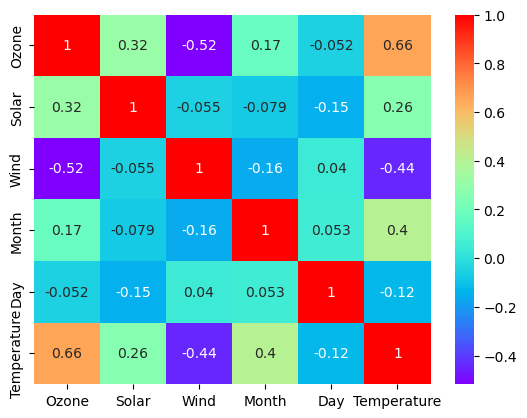

In [74]:
#Check for temp C and temperature column to be same
corr=weather.select_dtypes(include='number').corr()

import seaborn as sns
sns.heatmap(corr,annot=True, cmap='rainbow')

Since temp C and temperature are having perfect positive correlation, we assume that they are highly related or almost same, hence we can drop one of them

In [24]:
weather.drop(['Temp C',"Unnamed: 0","Year"],axis=1,inplace=True)

In [25]:
weather

,Ozone,Solar,Wind,Month,Day,Temperature,Weather
0,41.0,190.0,7.4,5,1,67,S
1,36.0,118.0,8.0,5,2,72,C
2,12.0,149.0,12.6,5,3,74,PS
3,18.0,313.0,11.5,5,4,62,S
4,NaN,NaN,14.3,5,5,56,S
...,...,...,...,...,...,...,...
153,41.0,190.0,7.4,5,1,67,C
154,30.0,193.0,6.9,9,26,70,PS
155,NaN,145.0,13.2,9,27,77,S
156,14.0,191.0,14.3,9,28,75,S


In [26]:
weather.isnull().sum()

Ozone          38
Solar           7
Wind            0
Month           0
Day             0
Temperature     0
Weather         3
dtype: int64

## Missing Value Treatment

<Axes: >

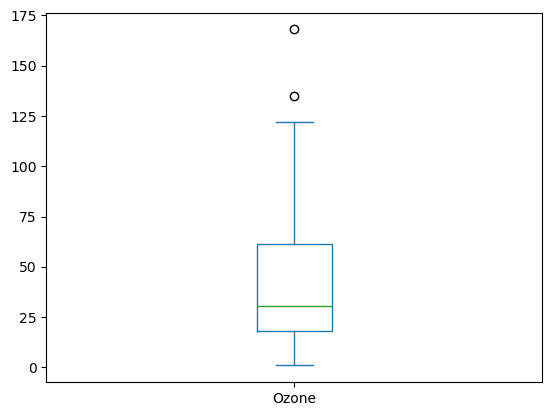

In [27]:
weather['Ozone'].plot(kind='box')

In [28]:
oz_med=weather['Ozone'].median()
oz_med

30.5

In [29]:
weather["Ozone"]=weather['Ozone'].fillna(oz_med)

In [30]:
weather['Ozone'].isnull().sum()

np.int64(0)

<Axes: >

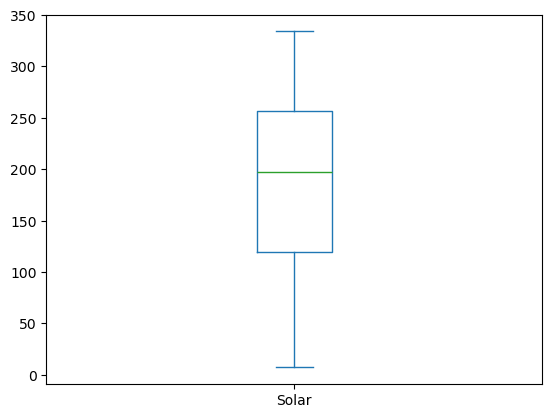

In [31]:
weather['Solar'].plot(kind='box')

In [32]:
weather['Solar'].fillna(weather['Solar'].mean(),inplace=True)

In [33]:
weather['Solar'].isnull().sum()

np.int64(0)

In [34]:
weather['Weather'].mode()[0]

'S'

In [35]:
weather['Weather']=weather['Weather'].fillna(weather['Weather'].mode()[0])

In [36]:
weather['Weather'].isnull().sum()

np.int64(0)

In [37]:
weather.dropna(inplace=True)

In [38]:
weather.isnull().sum()

Ozone          0
Solar          0
Wind           0
Month          0
Day            0
Temperature    0
Weather        0
dtype: int64

### Outlier Treatment

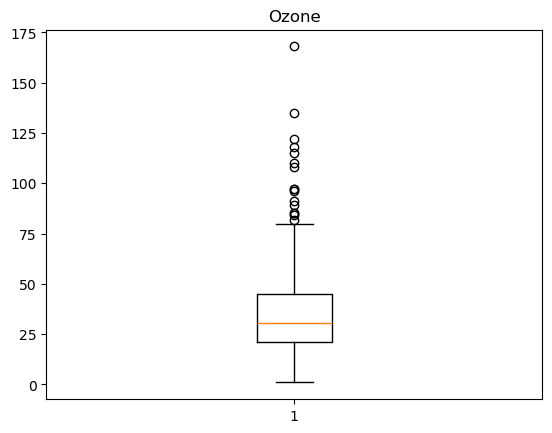

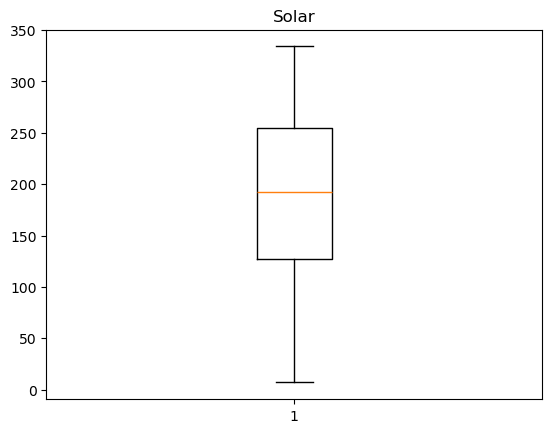

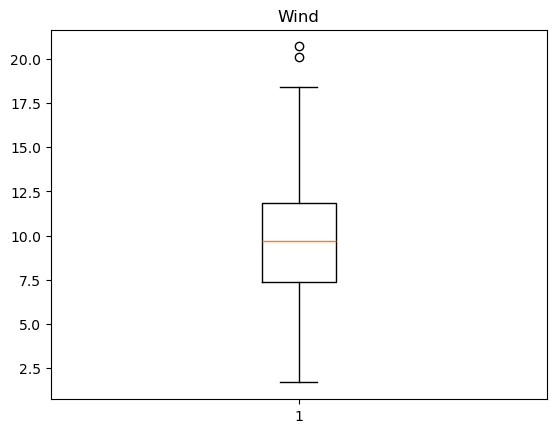

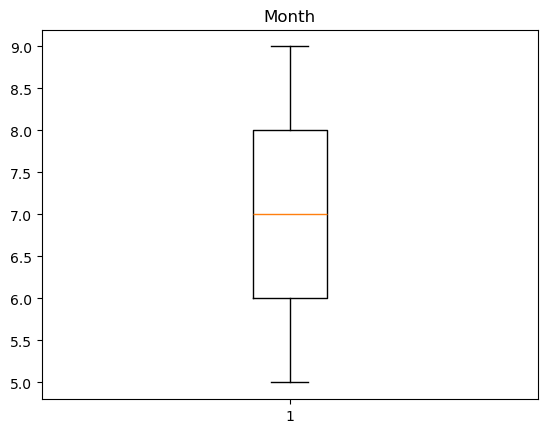

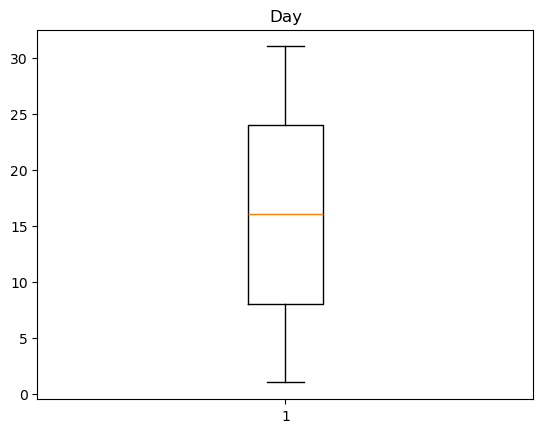

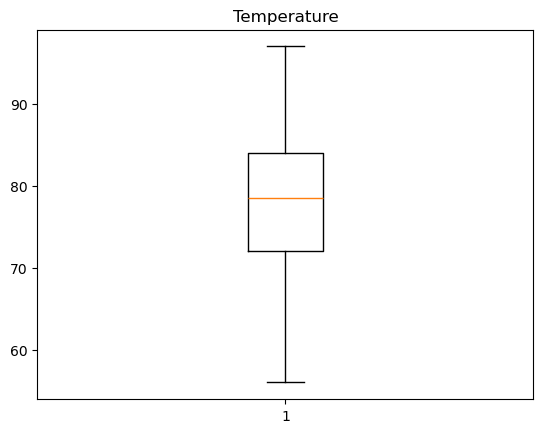

In [39]:
#to detect outlier
import matplotlib.pyplot as plt

for i in weather.columns:
  if weather[i].dtype!='object':
    plt.boxplot(weather[i])
    plt.title(i)
    plt.show()

In [40]:
import numpy as np
Q1=np.percentile(weather['Ozone'],25)   #numpy method of first quartile

Q3=weather['Ozone'].quantile(0.75)    #alt method of 3rd quartile using pandas

IQR=Q3-Q1

UE = Q3 + 1.5 *(IQR)

LE= Q1 - 1.5*(IQR)

In [41]:
weather[weather['Ozone']>UE]

,Ozone,Solar,Wind,Month,Day,Temperature,Weather
29,115.0,223.0,5.7,5,30,79,C
61,135.0,269.0,4.1,7,1,84,S
68,97.0,267.0,6.3,7,8,92,PS
69,97.0,272.0,5.7,7,9,92,C
70,85.0,175.0,7.4,7,10,89,PS
85,108.0,223.0,8.0,7,25,85,PS
88,82.0,213.0,7.4,7,28,88,S
98,122.0,255.0,4.0,8,7,89,C
99,89.0,229.0,10.3,8,8,90,PS
100,110.0,207.0,8.0,8,9,90,C


In [42]:
weather[weather['Ozone']<LE]

,Ozone,Solar,Wind,Month,Day,Temperature,Weather


In [43]:
#Capping and flooring method
weather.loc[weather["Ozone"]>UE,"Ozone"]=UE

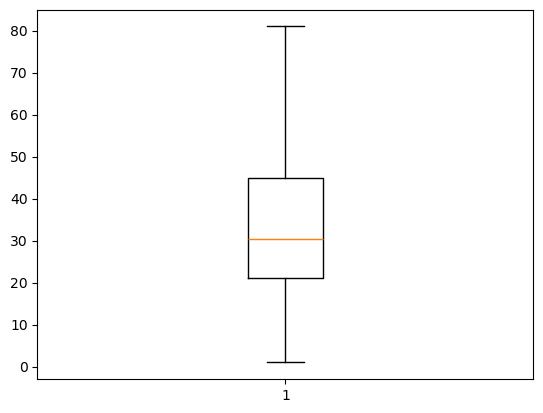

In [44]:
plt.boxplot(weather['Ozone'])
plt.show()

<Axes: >

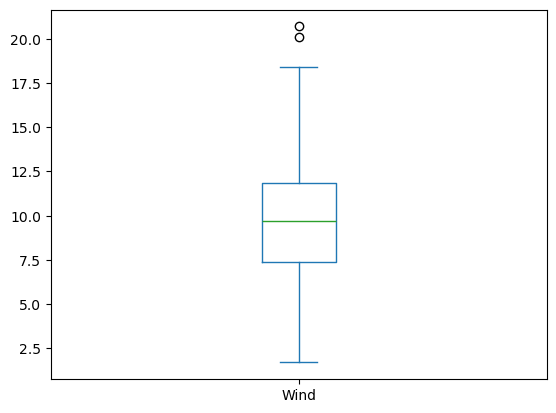

In [45]:
weather['Wind'].plot(kind="box")

In [46]:
#2. PERCENTILE METHOD
ue=weather['Wind'].quantile(0.95)
le=weather['Wind'].quantile(0.05)
print(ue,le)

15.5 4.6


In [47]:
weather.loc[weather['Wind']>ue,"Wind"]

8      20.1
17     18.4
21     16.6
24     16.6
33     16.1
47     20.7
147    16.6
Name: Wind, dtype: float64

In [48]:
weather.loc[weather['Wind']<le,"Wind"]

52     1.7
61     4.1
98     4.0
116    3.4
120    2.3
125    2.8
Name: Wind, dtype: float64

In [49]:
# Using 1.5 × IQR = detects moderate outliers
# Using 3 × IQR (or ue) = detects extreme outliers
# It is a standard statistical threshold
# 3 * ue = Want to capture wider range and making method less aggressive

In [50]:
weather.loc[weather['Wind']>3*ue,"Wind"]=3*ue
#weather.loc[weather['Wind']<3*le,"Wind"]=3*le

<Axes: ylabel='Density'>

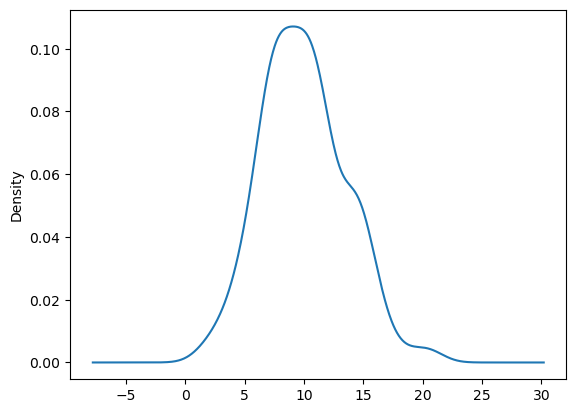

In [51]:
weather['Wind'].plot(kind='kde')

In [52]:
weather.head(10)

,Ozone,Solar,Wind,Month,Day,Temperature,Weather
0,41.0,190.000000,7.4,5,1,67,S
1,36.0,118.000000,8.0,5,2,72,C
2,12.0,149.000000,12.6,5,3,74,PS
3,18.0,313.000000,11.5,5,4,62,S
4,30.5,185.403974,14.3,5,5,56,S
5,28.0,185.403974,14.9,5,6,66,C
6,23.0,299.000000,8.6,5,7,65,PS
7,19.0,99.000000,13.8,5,8,59,C
8,8.0,19.000000,20.1,5,9,61,PS
9,30.5,194.000000,8.6,5,10,69,S


# **Transformations**


*   Convert Text data to numeric before model building



In [53]:
weather.head()

,Ozone,Solar,Wind,Month,Day,Temperature,Weather
0,41.0,190.000000,7.4,5,1,67,S
1,36.0,118.000000,8.0,5,2,72,C
2,12.0,149.000000,12.6,5,3,74,PS
3,18.0,313.000000,11.5,5,4,62,S
4,30.5,185.403974,14.3,5,5,56,S


In [56]:
# Encoding using Pandas dummy function
df = pd.get_dummies(data = weather, columns = ['Weather'])
df

,Ozone,Solar,Wind,Month,Day,Temperature,Weather_C,Weather_PS,Weather_S
0,41.0,190.000000,7.4,5,1,67,False,False,True
1,36.0,118.000000,8.0,5,2,72,True,False,False
2,12.0,149.000000,12.6,5,3,74,False,True,False
3,18.0,313.000000,11.5,5,4,62,False,False,True
4,30.5,185.403974,14.3,5,5,56,False,False,True
...,...,...,...,...,...,...,...,...,...
153,41.0,190.000000,7.4,5,1,67,True,False,False
154,30.0,193.000000,6.9,9,26,70,False,True,False
155,30.5,145.000000,13.2,9,27,77,False,False,True
156,14.0,191.000000,14.3,9,28,75,False,False,True


# **Scaling the data**

*   Bring down all columns to same scale

*   Normalization: Scales value within the range 0 to 1

*   Standardization: Uses Z score for scaling. Scale values in such a way that the mean=0 and std=1.

In [57]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [58]:
# Standardization
sc = StandardScaler() # ZScore=(x-x bar)/std

In [59]:
# sc.fit(): 1st Mean and Std of Ozone column is calculated. Then in numerator subtraction is done i.e. x-mean.
#           Then answer is divided by Std. Thus z-score is calculated. All the calculations are 
#           done by fit() function.
# sc.transform(): Original value in table is replaced by transform() function. i.e. 41.0 
# in Ozone column is replaced by it's z-score as 0.1901
# sc.fit_transform(): does both of the above tasks.

In [61]:
weather_numeric = weather.select_dtypes(include=['int64','float64'])
sc.fit_transform(weather_numeric)

array([[ 2.01690286e-01,  5.31653544e-02, -7.30713873e-01,
        -1.41690441e+00, -1.67319835e+00, -1.14759017e+00],
       [-2.11563237e-02, -7.79707460e-01, -5.59291761e-01,
        -1.41690441e+00, -1.56169884e+00, -6.12725133e-01],
       [-1.09082005e+00, -4.21109443e-01,  7.54944424e-01,
        -1.41690441e+00, -1.45019933e+00, -3.98779120e-01],
       [-8.23404118e-01,  1.47598975e+00,  4.40670554e-01,
        -1.41690441e+00, -1.33869982e+00, -1.68245520e+00],
       [-2.66287594e-01,  0.00000000e+00,  1.24064041e+00,
        -1.41690441e+00, -1.22720031e+00, -2.32429324e+00],
       [-3.77710899e-01,  0.00000000e+00,  1.41206252e+00,
        -1.41690441e+00, -1.11570080e+00, -1.25456317e+00],
       [-6.00557508e-01,  1.31404225e+00, -3.87869650e-01,
        -1.41690441e+00, -1.00420129e+00, -1.36153618e+00],
       [-7.78834796e-01, -9.99493342e-01,  1.09778865e+00,
        -1.41690441e+00, -8.92701779e-01, -2.00337422e+00],
       [-1.26909734e+00, -1.92490758e+00,  2.897

In [63]:
sc.fit_transform(df)

array([[ 0.20169029,  0.05316535, -0.73071387, ..., -0.6704784 ,
        -0.65070994,  1.24434203],
       [-0.02115632, -0.77970746, -0.55929176, ...,  1.49147236,
        -0.65070994, -0.80363756],
       [-1.09082005, -0.42110944,  0.75494442, ..., -0.6704784 ,
         1.53678305, -0.80363756],
       ...,
       [-0.26628759, -0.46738015,  0.92636654, ..., -0.6704784 ,
        -0.65070994,  1.24434203],
       [-1.00168141,  0.06473303,  1.24064041, ..., -0.6704784 ,
        -0.65070994,  1.24434203],
       [-0.82340412, -0.62932765, -0.55929176, ...,  1.49147236,
        -0.65070994, -0.80363756]], shape=(158, 9))

In [64]:
pd.DataFrame(sc.fit_transform(df)) # got table but column names are not visible. Index is there.

,0,1,2,3,4,5,6,7,8
0,0.201690,0.053165,-0.730714,-1.416904,-1.673198,-1.147590,-0.670478,-0.650710,1.244342
1,-0.021156,-0.779707,-0.559292,-1.416904,-1.561699,-0.612725,1.491472,-0.650710,-0.803638
2,-1.090820,-0.421109,0.754944,-1.416904,-1.450199,-0.398779,-0.670478,1.536783,-0.803638
3,-0.823404,1.475990,0.440671,-1.416904,-1.338700,-1.682455,-0.670478,-0.650710,1.244342
4,-0.266288,0.000000,1.240640,-1.416904,-1.227200,-2.324293,-0.670478,-0.650710,1.244342
...,...,...,...,...,...,...,...,...,...
153,0.201690,0.053165,-0.730714,-1.416904,-1.673198,-1.147590,1.491472,-0.650710,-0.803638
154,-0.288572,0.087868,-0.873566,1.372764,1.114289,-0.826671,-0.670478,1.536783,-0.803638
155,-0.266288,-0.467380,0.926367,1.372764,1.225789,-0.077860,-0.670478,-0.650710,1.244342
156,-1.001681,0.064733,1.240640,1.372764,1.337288,-0.291806,-0.670478,-0.650710,1.244342


In [65]:
df.columns # display all column names in sequence

Index(['Ozone', 'Solar', 'Wind', 'Month', 'Day', 'Temperature', 'Weather_C',
       'Weather_PS', 'Weather_S'],
      dtype='object')

In [66]:
# convert scaled array into dataframe. For this standardized data mean=0 and std=1
scaled_data = pd.DataFrame(sc.fit_transform(df),columns=df.columns)
scaled_data

,Ozone,Solar,Wind,Month,Day,Temperature,Weather_C,Weather_PS,Weather_S
0,0.201690,0.053165,-0.730714,-1.416904,-1.673198,-1.147590,-0.670478,-0.650710,1.244342
1,-0.021156,-0.779707,-0.559292,-1.416904,-1.561699,-0.612725,1.491472,-0.650710,-0.803638
2,-1.090820,-0.421109,0.754944,-1.416904,-1.450199,-0.398779,-0.670478,1.536783,-0.803638
3,-0.823404,1.475990,0.440671,-1.416904,-1.338700,-1.682455,-0.670478,-0.650710,1.244342
4,-0.266288,0.000000,1.240640,-1.416904,-1.227200,-2.324293,-0.670478,-0.650710,1.244342
...,...,...,...,...,...,...,...,...,...
153,0.201690,0.053165,-0.730714,-1.416904,-1.673198,-1.147590,1.491472,-0.650710,-0.803638
154,-0.288572,0.087868,-0.873566,1.372764,1.114289,-0.826671,-0.670478,1.536783,-0.803638
155,-0.266288,-0.467380,0.926367,1.372764,1.225789,-0.077860,-0.670478,-0.650710,1.244342
156,-1.001681,0.064733,1.240640,1.372764,1.337288,-0.291806,-0.670478,-0.650710,1.244342


In [67]:
# check if mean=0 and std=1
scaled_data.describe()

,Ozone,Solar,Wind,Month,Day,Temperature,Weather_C,Weather_PS,Weather_S
count,1.580000e+02,1.580000e+02,1.580000e+02,1.580000e+02,1.580000e+02,1.580000e+02,1.580000e+02,1.580000e+02,1.580000e+02
mean,-1.236704e-16,1.236704e-16,-2.923119e-16,-1.798842e-16,6.745659e-17,2.473408e-16,-6.464590e-17,-9.275281e-17,6.956461e-17
std,1.003180e+00,1.003180e+00,1.003180e+00,1.003180e+00,1.003180e+00,1.003180e+00,1.003180e+00,1.003180e+00,1.003180e+00
min,-1.581083e+00,-2.063720e+00,-2.359224e+00,-1.416904e+00,-1.673198e+00,-2.324293e+00,-6.704784e-01,-6.507099e-01,-8.036376e-01
25%,-6.896962e-01,-6.755984e-01,-7.307139e-01,-7.194873e-01,-8.927018e-01,-6.127251e-01,-6.704784e-01,-6.507099e-01,-8.036376e-01
50%,-2.662876e-01,8.208455e-02,-7.359578e-02,-2.207016e-02,-7.056931e-04,8.259941e-02,-6.704784e-01,-6.507099e-01,-8.036376e-01
75%,3.799676e-01,8.050644e-01,5.478094e-01,6.753470e-01,8.912904e-01,6.709509e-01,1.491472e+00,1.536783e+00,1.244342e+00
max,1.984463e+00,1.718911e+00,3.069143e+00,1.372764e+00,1.671787e+00,2.061600e+00,1.491472e+00,1.536783e+00,1.244342e+00


In [68]:
mn = MinMaxScaler()

In [69]:
df.columns

Index(['Ozone', 'Solar', 'Wind', 'Month', 'Day', 'Temperature', 'Weather_C',
       'Weather_PS', 'Weather_S'],
      dtype='object')

In [71]:
minmax_scaled = pd.DataFrame(mn.fit_transform(df), columns=df.columns)
minmax_scaled # converted value is in range of 0 and 1

,Ozone,Solar,Wind,Month,Day,Temperature,Weather_C,Weather_PS,Weather_S
0,0.50000,0.559633,0.300000,0.0,0.000000,0.268293,0.0,0.0,1.0
1,0.43750,0.339450,0.331579,0.0,0.033333,0.390244,1.0,0.0,0.0
2,0.13750,0.434251,0.573684,0.0,0.066667,0.439024,0.0,1.0,0.0
3,0.21250,0.935780,0.515789,0.0,0.100000,0.146341,0.0,0.0,1.0
4,0.36875,0.545578,0.663158,0.0,0.133333,0.000000,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
153,0.50000,0.559633,0.300000,0.0,0.000000,0.268293,1.0,0.0,0.0
154,0.36250,0.568807,0.273684,1.0,0.833333,0.341463,0.0,1.0,0.0
155,0.36875,0.422018,0.605263,1.0,0.866667,0.512195,0.0,0.0,1.0
156,0.16250,0.562691,0.663158,1.0,0.900000,0.463415,0.0,0.0,1.0


In [72]:
minmax_scaled.describe() # check min and max values as 0 and 1 respectively

,Ozone,Solar,Wind,Month,Day,Temperature,Weather_C,Weather_PS,Weather_S
count,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000,158.000000
mean,0.443434,0.545578,0.434610,0.507911,0.500211,0.529948,0.310127,0.297468,0.392405
std,0.281354,0.265207,0.184803,0.359605,0.299906,0.228729,0.464016,0.458598,0.489839
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.250000,0.366972,0.300000,0.250000,0.233333,0.390244,0.000000,0.000000,0.000000
50%,0.368750,0.567278,0.421053,0.500000,0.500000,0.548780,0.000000,0.000000,0.000000
75%,0.550000,0.758410,0.535526,0.750000,0.766667,0.682927,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
